# Notebook 1 — Data Cleaning and Exploratory Data Analysis

**Project:** Will the 10-year US Treasury yield rise or fall over the next month?
**Author:** Arun Kumar Pandey

This is the first of three notebooks:

| # | Notebook | What it does |
|---|----------|--------------|
| **1** | **Data cleaning and EDA** (this one) | Loads the raw data, checks its quality, builds the features and the target, explores the data |
| 2 | [Yield curve PCA and regimes](2_yield_curve_pca_and_regimes.ipynb) | Unsupervised learning: what drives the curve, and which "rate regimes" exist |
| 3 | [Modeling and evaluation](3_modeling_and_evaluation.ipynb) | Supervised learning: five classifiers, cross-validation, grid search, evaluation |

## 1. Business understanding

The 10-year US Treasury yield is the world's benchmark interest rate. Banks, insurers, pension funds and
corporate treasurers all hold bonds whose value **falls when yields rise**. A view on whether the 10-year yield
is more likely to go **up or down over the next month (21 trading days)** helps them decide how much interest-rate
risk ("duration") to hold and how much to hedge.

**The question for this project:** using only information available today — the shape of the yield curve,
the policy rate, inflation expectations and market risk sentiment — can a machine-learning classifier predict the
*direction* of the 10-year yield one month ahead better than simple rules of thumb?

**What counts as success.** The bond market is one of the most efficient markets in the world, so we expect a
*small* edge at best. We judge every model against two baselines: always predicting the most common outcome, and
"persistence" (assume last month's direction continues).

## 2. Setup

In [1]:
# Core libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller

# Display and plotting defaults
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Project constants
DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"
IMG_DIR = Path("../images")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIR.mkdir(parents=True, exist_ok=True)

START_DATE = "2001-08-01"  # first full month in which the 1-month bill is published
HORIZON = 21               # prediction horizon in trading days (about one calendar month)

## 3. Data acquisition

All data comes from **FRED** (Federal Reserve Bank of St. Louis), which republishes the Federal Reserve's official
H.15 interest-rate release. It is free, authoritative and needs no API key. This is the same underlying source as the
Kaggle dataset *US Treasury Yields (guillemservera/us-treasury-yields-daily)* named in the project proposal, but
downloaded directly so the sample runs up to the present day.

| Source series | Friendly name | Why it is included |
|---|---|---|
| `DGS1MO` … `DGS30` (11 series) | `1M` … `30Y` | The yield curve itself: eleven maturities from 1 month to 30 years |
| `DFF` | `fed_funds` | The Federal Reserve's policy rate — the anchor for short-term yields |
| `T10YIE` | `breakeven_10y` | Market-implied 10-year inflation expectation |
| `VIXCLS` | `vix` | Equity "fear gauge" — a proxy for risk sentiment and flight-to-safety |
| `DCOILBRENTEU` | `brent_oil` | Brent crude — an energy-driven inflation impulse |
| `DTWEXBGS` | `dollar_index` | Broad US dollar index — global demand for dollar assets |
| `CPIAUCSL` | `cpi` | Consumer price index (monthly) — realised inflation |

*Multiple sources, one purpose:* the curve tells us what the market is pricing; the controls describe the
economic forces that move it.

> **Note on a dropped series.** An earlier version also used the high-yield credit spread (`BAMLH0A0HYM2`).
> Its download came back truncated (219 rows instead of ~6,000), which silently shrank the dataset and produced a
> fake "perfect" model. It was removed — the VIX carries similar risk-sentiment information — and the coverage
> checks below were added so a truncated download now stops the notebook instead of corrupting results.

In [2]:
def read_fred_csv(path):
    # FRED marks missing values with "." (older files) or an empty cell (newer files)
    return pd.read_csv(path, parse_dates=["observation_date"], index_col="observation_date",
                       na_values=[".", ""])

# FRED may split a download into several files (one per frequency), so read every raw CSV under data/
# (excluding our own processed outputs) and join them on date. Files are identified by contents, not name.
raw_files = sorted(p for p in DATA_DIR.rglob("*.csv") if PROCESSED_DIR not in p.parents)
frames = {str(p.relative_to(DATA_DIR)): read_fred_csv(p) for p in raw_files}
for name, f in frames.items():
    print(f"{name:<32} {f.shape[0]:>6,} rows  {f.index.min():%Y-%m-%d} to {f.index.max():%Y-%m-%d}  "
          f"series: {', '.join(f.columns)}")

monthly_frames = [f for f in frames.values() if "CPIAUCSL" in f.columns]
raw_cpi = monthly_frames[0][["CPIAUCSL"]]
raw_daily = pd.concat([f for f in frames.values() if "CPIAUCSL" not in f.columns], axis=1).sort_index()
raw_daily = raw_daily.loc[:, ~raw_daily.columns.duplicated()]
print(f"\nCombined daily table: {raw_daily.shape[0]:,} dates x {raw_daily.shape[1]} series")
raw_daily.loc[START_DATE:].dropna(how="all").tail()

raw/cpi_monthly.csv                 957 rows  1947-01-01 to 2026-09-01  series: CPIAUCSL
raw/fed_funds_daily.csv          26,398 rows  1954-07-01 to 2026-10-08  series: DFF
raw/financial_conditions_weekly.csv  2,910 rows  1971-01-08 to 2026-10-09  series: NFCI
raw/jobless_claims_weekly.csv     3,119 rows  1967-01-07 to 2026-10-10  series: ICSA
raw/market_controls_daily.csv    10,278 rows  1987-05-20 to 2026-10-09  series: T10YIE, DCOILBRENTEU, DTWEXBGS
raw/term_premium_daily.csv        9,594 rows  1990-01-02 to 2026-10-09  series: THREEFYTP10
raw/treasury_yields_daily.csv    16,898 rows  1962-01-02 to 2026-10-08  series: DGS1MO, DGS3MO, DGS6MO, DGS1, DGS2, DGS3, DGS5, DGS7, DGS10, DGS20, DGS30
raw/vix_daily.csv                 9,594 rows  1990-01-02 to 2026-10-09  series: VIXCLS

Combined daily table: 26,400 dates x 19 series


,DFF,NFCI,ICSA,T10YIE,DCOILBRENTEU,DTWEXBGS,THREEFYTP10,DGS1MO,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS7,DGS10,DGS20,DGS30,VIXCLS
observation_date,,,,,,,,,,,,,,,,,,,
2026-10-06,3.88,NaN,NaN,2.36,125.44,NaN,1.084,4.06,4.21,4.28,4.46,4.79,4.88,5.03,5.15,5.27,5.68,5.64,15.01
2026-10-07,3.88,NaN,NaN,2.36,NaN,NaN,1.086,4.07,4.22,4.28,4.42,4.77,4.87,5.03,5.15,5.28,5.71,5.67,15.08
2026-10-08,3.88,NaN,NaN,2.35,NaN,NaN,1.069,4.14,4.23,4.30,4.44,4.75,4.85,4.99,5.11,5.22,5.64,5.60,15.41
2026-10-09,NaN,-0.499,NaN,2.33,NaN,NaN,1.073,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.84
2026-10-10,NaN,NaN,199000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Map FRED codes to readable names and confirm every expected series is present
TENOR_MAP = {"DGS1MO": "1M", "DGS3MO": "3M", "DGS6MO": "6M", "DGS1": "1Y", "DGS2": "2Y", "DGS3": "3Y",
             "DGS5": "5Y", "DGS7": "7Y", "DGS10": "10Y", "DGS20": "20Y", "DGS30": "30Y"}
CONTROL_MAP = {"DFF": "fed_funds", "T10YIE": "breakeven_10y", "VIXCLS": "vix",
               "DCOILBRENTEU": "brent_oil", "DTWEXBGS": "dollar_index"}
MATURITY_YEARS = {"1M": 1/12, "3M": 0.25, "6M": 0.5, "1Y": 1, "2Y": 2, "3Y": 3,
                  "5Y": 5, "7Y": 7, "10Y": 10, "20Y": 20, "30Y": 30}

missing = [c for c in list(TENOR_MAP) + list(CONTROL_MAP) if c not in raw_daily.columns]
assert not missing, f"Series missing from the download: {missing}"
print(f"All {len(TENOR_MAP)} tenors and {len(CONTROL_MAP)} control series found.")

TENORS = list(TENOR_MAP.values())
# Keep only the series this notebook uses (other files in data/raw are used in Notebook 4)
daily = raw_daily[list(TENOR_MAP) + list(CONTROL_MAP)].rename(columns={**TENOR_MAP, **CONTROL_MAP})

All 11 tenors and 5 control series found.


## 4. Data cleaning and quality audit

FRED's combined file contains a row for **every calendar date on which any series has a value**: the fed funds rate is
published on weekends, Brent oil follows London holidays, and so on. The steps below:

1. **Fix the calendar** — keep only US Treasury trading days (days on which the 10-year yield is published).
2. **Audit missing values** — how much of each series is missing, and is any gap long?
3. **Check for stale data** — the longest run of identical consecutive values (a frozen feed looks like this).
4. **Fill only short gaps** — forward-fill at most a few days (holiday mismatches), never long gaps.
5. **Guard against truncated downloads** — every series must cover at least half of the sample, or the notebook stops.

In [4]:
# Step 1: Treasury trading calendar from START_DATE
panel = daily.loc[daily.index >= START_DATE]
panel = panel.loc[panel["10Y"].notna()].copy()
print(f"Treasury trading days since {START_DATE}: {len(panel):,}")

def longest_nan_run(s):
    # length of the longest consecutive block of missing values
    is_na = s.isna().astype(int)
    return int(is_na.groupby((is_na == 0).cumsum()).sum().max())

def longest_stale_run(s):
    # longest run of identical consecutive (non-missing) values
    x = s.dropna()
    return int(x.groupby((x != x.shift()).cumsum()).size().max())

# Steps 2 and 3: quality audit table
audit = pd.DataFrame({
    "first_date": panel.apply(lambda s: s.first_valid_index().date()),
    "coverage_%": panel.notna().mean() * 100,
    "longest_gap_days": panel.apply(longest_nan_run),
    "longest_stale_run": panel.apply(longest_stale_run),
})
audit.round(1)

Treasury trading days since 2001-08-01: 6,299


,first_date,coverage_%,longest_gap_days,longest_stale_run
1M,2001-08-01,100.0,0,18
3M,2001-08-01,100.0,0,17
6M,2001-08-01,100.0,0,16
1Y,2001-08-01,100.0,0,10
2Y,2001-08-01,100.0,0,8
3Y,2001-08-01,100.0,0,7
5Y,2001-08-01,100.0,0,5
7Y,2001-08-01,100.0,0,4
10Y,2001-08-01,100.0,0,5
20Y,2001-08-01,100.0,0,5


**Reading the audit.**

- **All eleven tenors are complete** on the Treasury calendar. (The Treasury did not issue 30-year bonds between 2002 and
  2006; FRED's 30-year series covers that period with the Treasury's published estimate, so there is no gap to fill.)
  The code still applies a rule — any tenor with a gap longer than 60 trading days is excluded from modeling — so the
  pipeline stays safe if a future download has holes.
- The **dollar index starts in 2006** and **breakeven inflation** in 2003 (the "longest gap" for these is simply the time
  before the series began), so the modeling sample starts once all inputs exist.
- **Stale runs:** market prices never repeat for more than a few days. The longer runs (fed funds up to ~290 days,
  1-month bill ~18 days) are genuine — the policy rate sat unchanged at the zero lower bound — not a frozen feed.

In [5]:
# Step 4: forward-fill short holiday gaps only (max 5 trading days); long gaps stay missing
MAX_FILL_DAYS = 5
clean = panel.ffill(limit=MAX_FILL_DAYS)

# Tenors usable for PCA/modeling: no gap longer than 60 trading days (a safety rule for future downloads)
MODEL_TENORS = [t for t in TENORS if audit.loc[t, "longest_gap_days"] <= 60]
excluded = sorted(set(TENORS) - set(MODEL_TENORS))
print("Tenors used for PCA/modeling:", MODEL_TENORS)
print("Tenors excluded (long gap):  ", excluded)

# Step 5: download-integrity guard - every control series must cover at least 50% of the sample
MIN_COVERAGE = 0.50
coverage = clean[list(CONTROL_MAP.values())].notna().mean()
print("\nControl-series coverage after cleaning:")
print(coverage.map("{:.1%}".format).to_string())
too_short = coverage[coverage < MIN_COVERAGE]
if not too_short.empty:
    raise ValueError(f"Possible truncated download - coverage below {MIN_COVERAGE:.0%}: {too_short.to_dict()}")
print("\nIntegrity check passed: no truncated series.")

Tenors used for PCA/modeling: ['1M', '3M', '6M', '1Y', '2Y', '3Y', '5Y', '7Y', '10Y', '20Y', '30Y']
Tenors excluded (long gap):   []

Control-series coverage after cleaning:
fed_funds        100.0%
breakeven_10y     94.4%
vix              100.0%
brent_oil        100.0%
dollar_index      82.5%

Integrity check passed: no truncated series.


### Inflation (CPI) without look-ahead bias

CPI is monthly, and the figure for a month is published around the middle of the *following* month. If we simply
attached January's CPI to January's trading days we would be using information nobody had yet (look-ahead bias).
We therefore attach each month's CPI only from **the 15th of the following month**, then carry it forward.

In [6]:
cpi = raw_cpi.rename(columns={"CPIAUCSL": "cpi"})
cpi["cpi_yoy"] = cpi["cpi"].pct_change(12, fill_method=None) * 100                       # year-on-year inflation, %
cpi.index = cpi.index + pd.offsets.MonthBegin(1) + pd.Timedelta(days=14)  # date it became public

# Align onto trading days: each day sees the most recently *published* CPI
clean["cpi_yoy"] = cpi["cpi_yoy"].reindex(clean.index, method="ffill")
clean[["cpi_yoy"]].dropna().tail(3)

,cpi_yoy
observation_date,
2026-10-06,3.353
2026-10-07,3.353
2026-10-08,3.353


## 5. Feature engineering

Every feature uses **only information available on the day of the forecast**. Yield changes are expressed in
**basis points (bp)** — 1 bp = 0.01 percentage point — the unit bond traders use.

| Feature | Meaning in plain words |
|---|---|
| `level_10y_vs_1y` | 10-year yield minus its own 1-year average (%): is the yield high or low *relative to its recent past*? |
| `slope_10y_2y`, `slope_10y_3m` | How steep the curve is; negative = **inverted curve**, a classic recession signal |
| `butterfly_2s5s10s` | Curvature: is the middle of the curve high or low relative to the ends? |
| `mom_10y_21d`, `mom_10y_63d` | Momentum: how much the 10-year moved over the last 1 and 3 months (bp) |
| `vol_10y_21d` | How volatile the 10-year has been over the last month (bp per day) |
| `spread_10y_fedfunds` | 10-year yield minus the policy rate: how far long rates sit above policy |
| `fedfunds_chg_63d` | Change in the policy rate over 3 months: is the Fed hiking or cutting? |
| `real_yield_vs_1y` | Real yield (10-year yield minus expected inflation) relative to its 1-year average |
| `cpi_yoy_chg_3m` | Change in the latest published annual inflation rate over 3 months: is inflation accelerating? |
| `vix`, `vix_chg_21d` | Market fear level and its 1-month change |
| `oil_ret_21d`, `dollar_ret_21d` | 1-month % change in oil and in the dollar |

**Why deviations instead of raw levels?** Section 7 shows that the 10-year yield *level* is non-stationary — it
trended down for most of 2001–2021, then jumped. A model fed raw levels learns "high yields are followed by falls"
from that long decline, a pattern that breaks as soon as the trend changes. Measuring each level against its own
1-year average keeps the information ("rates are unusually high right now") without the trend.

**Target.** `target_up` = 1 if the 10-year yield is **higher 21 trading days later**, otherwise 0.

In [7]:
features = pd.DataFrame(index=clean.index)
y10 = clean["10Y"]

# Curve shape
features["level_10y_vs_1y"] = y10 - y10.rolling(252).mean()
features["slope_10y_2y"] = clean["10Y"] - clean["2Y"]
features["slope_10y_3m"] = clean["10Y"] - clean["3M"]
features["butterfly_2s5s10s"] = 2 * clean["5Y"] - clean["2Y"] - clean["10Y"]

# Momentum and volatility of the 10-year (bp)
features["mom_10y_21d"] = (y10 - y10.shift(21)) * 100
features["mom_10y_63d"] = (y10 - y10.shift(63)) * 100
features["vol_10y_21d"] = (y10.diff() * 100).rolling(21).std()

# Monetary policy and inflation
features["spread_10y_fedfunds"] = y10 - clean["fed_funds"]
features["fedfunds_chg_63d"] = (clean["fed_funds"] - clean["fed_funds"].shift(63)) * 100
real_yield = y10 - clean["breakeven_10y"]
features["real_yield_vs_1y"] = real_yield - real_yield.rolling(252).mean()
features["cpi_yoy_chg_3m"] = clean["cpi_yoy"] - clean["cpi_yoy"].shift(63)

# Risk sentiment and global drivers
features["vix"] = clean["vix"]
features["vix_chg_21d"] = clean["vix"] - clean["vix"].shift(21)
features["oil_ret_21d"] = clean["brent_oil"].pct_change(21, fill_method=None) * 100
features["dollar_ret_21d"] = clean["dollar_index"].pct_change(21, fill_method=None) * 100

FEATURES = list(features.columns)

# Target: direction of the 10-year yield over the next HORIZON trading days
features["fwd_chg_10y_bp"] = (y10.shift(-HORIZON) - y10) * 100
features["target_up"] = (features["fwd_chg_10y_bp"] > 0).astype(int)
features.loc[features["fwd_chg_10y_bp"].isna(), "target_up"] = np.nan  # last 21 days have no known outcome

print(f"{len(FEATURES)} features created")

15 features created


In [8]:
# Row-attrition guard: show what each column costs before dropping incomplete rows
rows_before = len(features)
lost_by_col = features.isna().sum().sort_values(ascending=False)
print("Rows lost to missing values, by column (top 6):")
print(lost_by_col.head(6).to_string())

model_df = features.dropna().copy()
model_df["target_up"] = model_df["target_up"].astype(int)
lost_share = 1 - len(model_df) / rows_before
print(f"\nRows before: {rows_before:,}   after: {len(model_df):,}   removed: {lost_share:.1%}")
assert lost_share < 0.5, "More than half the rows were removed - check for a truncated series."
print(f"Modeling sample: {model_df.index.min():%Y-%m-%d} to {model_df.index.max():%Y-%m-%d}")

Rows lost to missing values, by column (top 6):
dollar_ret_21d      1123
real_yield_vs_1y     603
level_10y_vs_1y      251
cpi_yoy_chg_3m       101
mom_10y_63d           63
fedfunds_chg_63d      63

Rows before: 6,299   after: 5,115   removed: 18.8%
Modeling sample: 2006-02-02 to 2026-09-09


The rows removed are expected: the dollar index starts in 2006, the 1-year averages and 3-month changes need a
warm-up window, and the final 21 days have no known outcome yet. No single column wipes out the dataset.

## 6. Exploratory data analysis

### 6.1 The yield curve over time

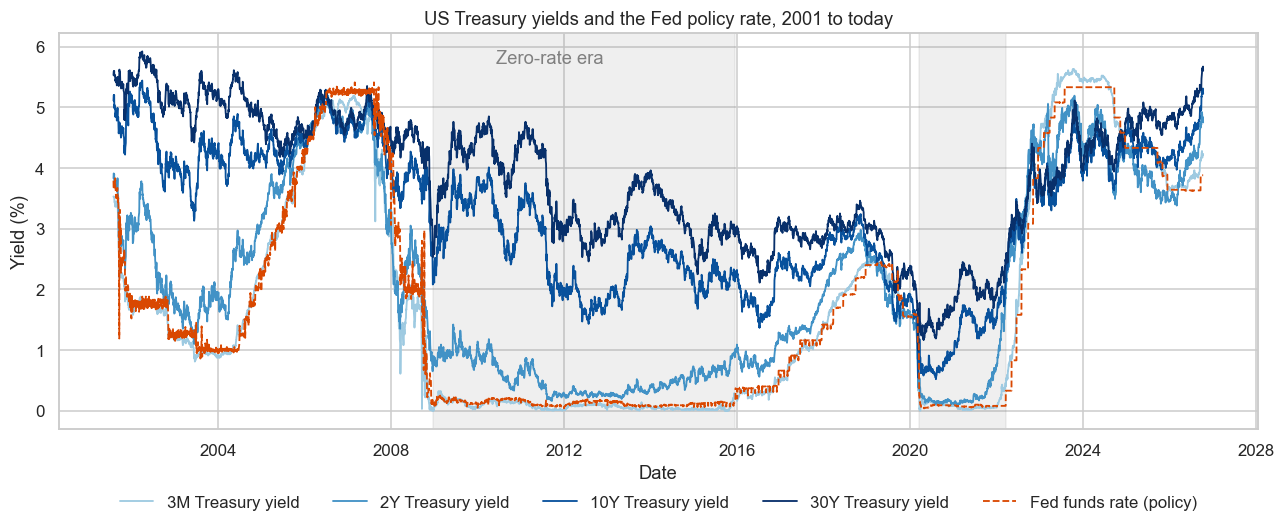

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
for tenor, colour in zip(["3M", "2Y", "10Y", "30Y"], ["#9ecae1", "#4292c6", "#08519c", "#08306b"]):
    ax.plot(clean.index, clean[tenor], label=f"{tenor} Treasury yield", lw=1.2, color=colour)
ax.plot(clean.index, clean["fed_funds"], label="Fed funds rate (policy)", color="#d94801", lw=1.2, ls="--")

# Shade the zero-interest-rate periods for context
for start, end in [("2008-12-16", "2015-12-16"), ("2020-03-16", "2022-03-16")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="grey", alpha=0.12)
ax.text(pd.Timestamp("2010-06-01"), ax.get_ylim()[1] * 0.92, "Zero-rate era", color="grey")

ax.set_title("US Treasury yields and the Fed policy rate, 2001 to today")
ax.set_xlabel("Date")
ax.set_ylabel("Yield (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=5, frameon=False)
fig.tight_layout()
fig.savefig(IMG_DIR / "01_yield_history.png", bbox_inches="tight")
plt.show()

**What we see.** Yields fell for most of two decades, sat near zero after the 2008 crisis and again during COVID,
then jumped in 2022–23 in the fastest Fed tightening cycle in four decades. Short rates (3M) follow the Fed almost
exactly; long rates (10Y, 30Y) move more slowly and reflect the market's long-run view.

### 6.2 Curve inversions — when short rates exceed long rates

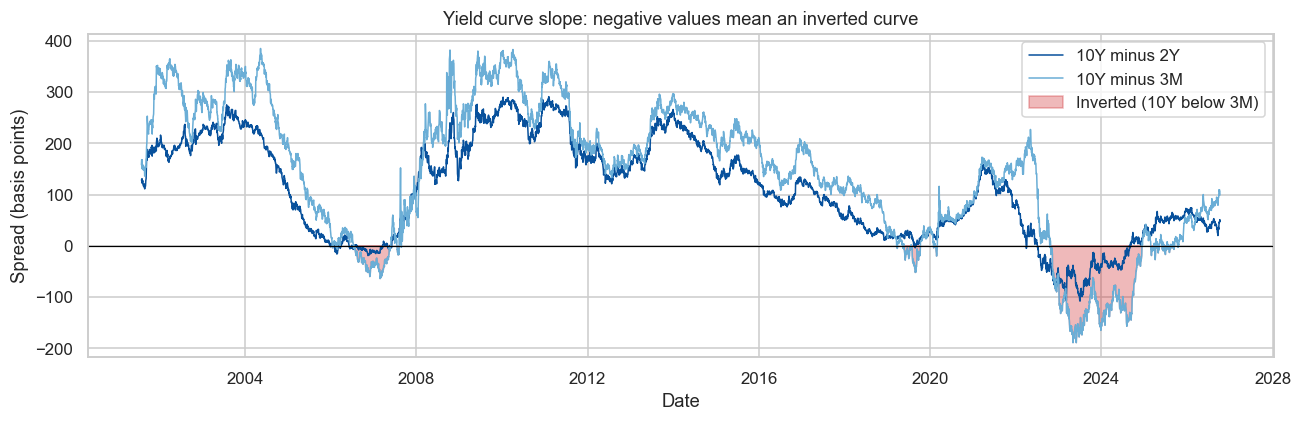

Share of trading days with an inverted 10Y-3M curve: 15.6%


In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
for col, label, colour in [("slope_10y_2y", "10Y minus 2Y", "#08519c"), ("slope_10y_3m", "10Y minus 3M", "#6baed6")]:
    s = features[col] * 100
    ax.plot(s.index, s, label=label, color=colour, lw=1)
inverted = features["slope_10y_3m"] < 0
ax.fill_between(features.index, 0, features["slope_10y_3m"] * 100, where=inverted,
                color="#cb181d", alpha=0.3, label="Inverted (10Y below 3M)")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Yield curve slope: negative values mean an inverted curve")
ax.set_xlabel("Date")
ax.set_ylabel("Spread (basis points)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(IMG_DIR / "02_curve_slope_inversions.png", bbox_inches="tight")
plt.show()

print(f"Share of trading days with an inverted 10Y-3M curve: {inverted.mean():.1%}")

### 6.3 What the whole curve looked like on key dates

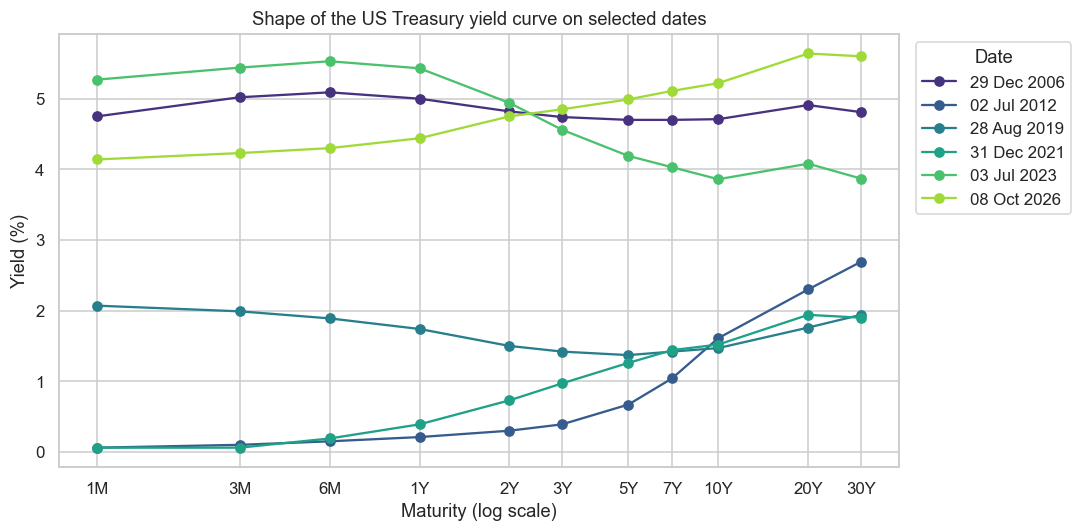

In [11]:
snapshot_dates = ["2006-12-29", "2012-07-02", "2019-08-28", "2021-12-31", "2023-07-03", str(clean.index[-1].date())]
maturities = [MATURITY_YEARS[t] for t in TENORS]

fig, ax = plt.subplots(figsize=(10, 5))
palette = sns.color_palette("viridis", len(snapshot_dates))
for date, colour in zip(snapshot_dates, palette):
    row = clean.loc[clean.index.asof(pd.Timestamp(date)), TENORS]
    ax.plot(maturities, row.values, marker="o", label=pd.Timestamp(row.name).strftime("%d %b %Y"), color=colour)
ax.set_xscale("log")
ax.set_xticks(maturities)
ax.set_xticklabels(TENORS)
ax.set_title("Shape of the US Treasury yield curve on selected dates")
ax.set_xlabel("Maturity (log scale)")
ax.set_ylabel("Yield (%)")
ax.legend(title="Date", loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

The curve takes very different shapes: **upward sloping** (2012, 2021, 2026), **flat or mildly inverted** (2006, 2019)
and **deeply inverted** (July 2023, when 6-month bills yielded about 1.7 points more than the 10-year). These shape changes are exactly what Notebook 2 summarises with PCA.

### 6.4 Distribution of daily changes in the 10-year yield (continuous variable)

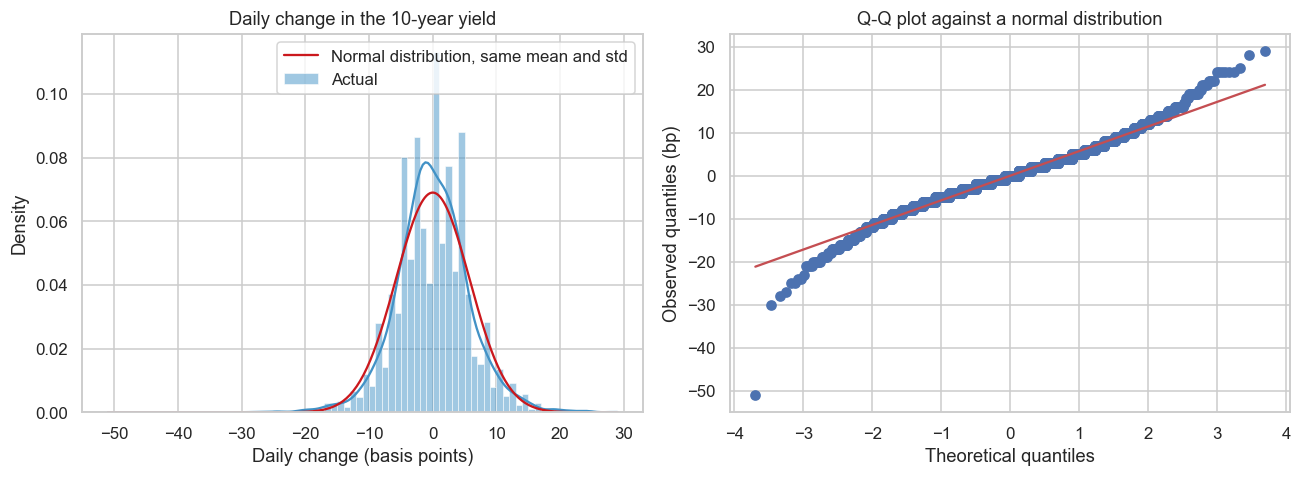

Mean 0.00 bp | Std 5.78 bp | Skew -0.04 | Excess kurtosis 2.49
Jarque-Bera normality test: statistic=1,628, p-value=0


In [12]:
daily_chg_bp = (clean["10Y"].diff() * 100).dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(daily_chg_bp, bins=80, stat="density", kde=True, color="#4292c6", ax=axes[0], label="Actual")
grid = np.linspace(daily_chg_bp.min(), daily_chg_bp.max(), 300)
axes[0].plot(grid, stats.norm.pdf(grid, daily_chg_bp.mean(), daily_chg_bp.std()), color="#cb181d",
             lw=1.5, label="Normal distribution, same mean and std")
axes[0].set_title("Daily change in the 10-year yield")
axes[0].set_xlabel("Daily change (basis points)")
axes[0].set_ylabel("Density")
axes[0].legend()

stats.probplot(daily_chg_bp, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot against a normal distribution")
axes[1].set_xlabel("Theoretical quantiles")
axes[1].set_ylabel("Observed quantiles (bp)")
fig.tight_layout()
plt.show()

jb_stat, jb_p = stats.jarque_bera(daily_chg_bp)
print(f"Mean {daily_chg_bp.mean():.2f} bp | Std {daily_chg_bp.std():.2f} bp | "
      f"Skew {daily_chg_bp.skew():.2f} | Excess kurtosis {daily_chg_bp.kurt():.2f}")
print(f"Jarque-Bera normality test: statistic={jb_stat:,.0f}, p-value={jb_p:.2g}")

**Interpretation.** Daily moves average roughly zero, with a typical size of a few basis points. The distribution has
**fat tails** (positive excess kurtosis): large moves happen far more often than a normal distribution would predict,
and the Jarque-Bera test firmly rejects normality. In practice this means models and risk limits that assume
"normal" markets will underestimate extreme days.

### 6.5 How closely do different maturities move together?

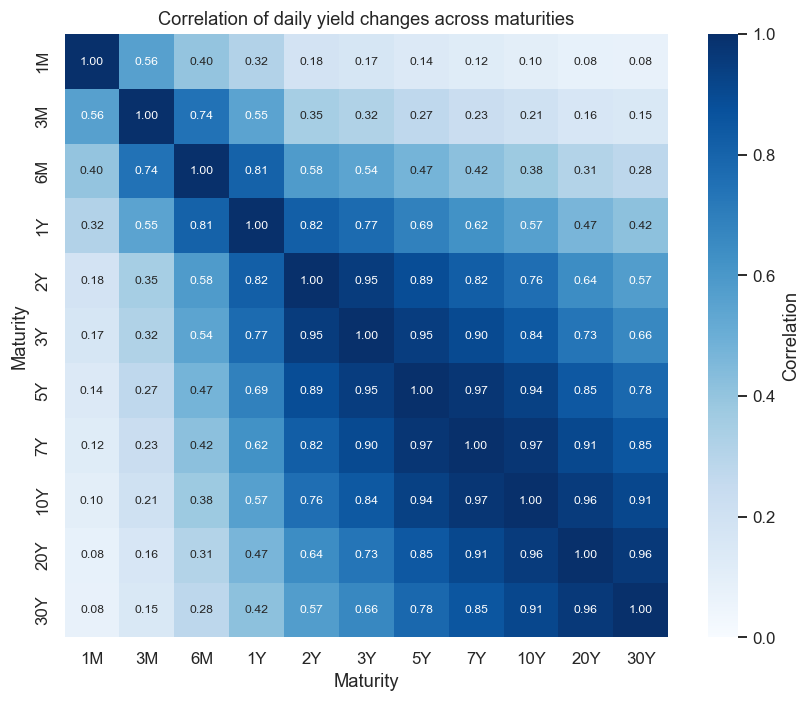

In [13]:
tenor_changes = clean[MODEL_TENORS].diff().dropna() * 100
corr = tenor_changes.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True,
            cbar_kws={"label": "Correlation"}, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation of daily yield changes across maturities")
ax.set_xlabel("Maturity")
ax.set_ylabel("Maturity")
fig.tight_layout()
plt.show()

From two years out, neighbouring maturities move almost in lockstep (correlations of 0.9 and above), and the
correlation fades as maturities get further apart. The shortest bills behave very differently: the 1-month yield is
almost uncorrelated with the 10-year (about 0.1) because it is tied to the Fed's policy rate, not to long-run views. Such strong co-movement means a few underlying
factors drive the whole curve — the motivation for PCA in Notebook 2.

### 6.6 The target: how often does the 10-year rise over the next month? (categorical variable)

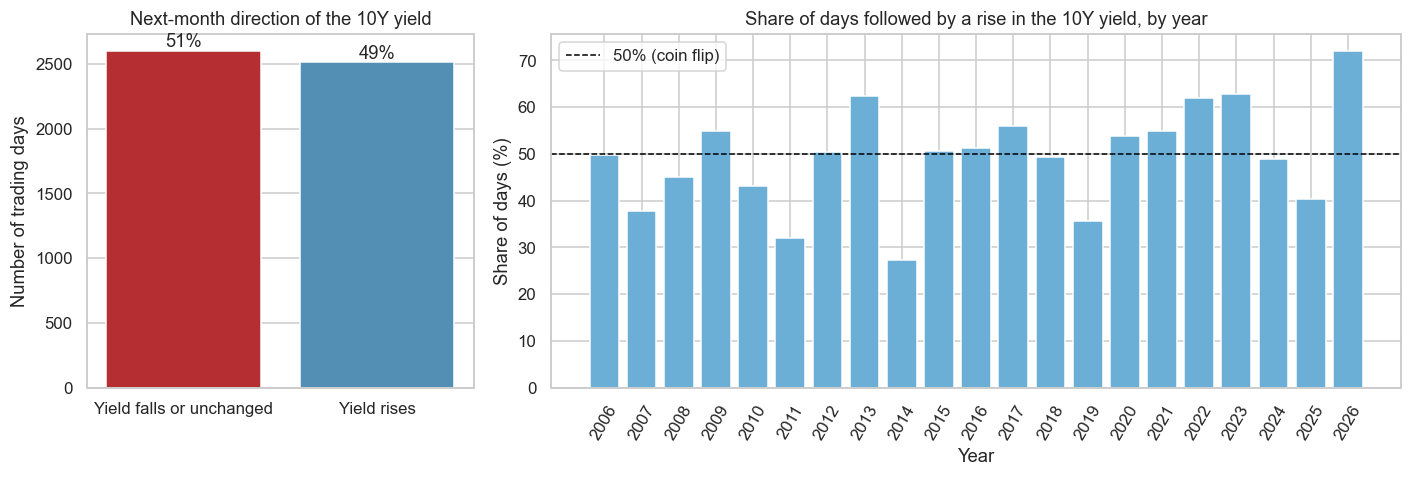

In [14]:
target_labels = model_df["target_up"].map({1: "Yield rises", 0: "Yield falls or unchanged"})
yearly_up = model_df.groupby(model_df.index.year)["target_up"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2.2]})
sns.countplot(x=target_labels, hue=target_labels, palette=["#4292c6", "#cb181d"], legend=False, ax=axes[0],
              order=["Yield falls or unchanged", "Yield rises"])
axes[0].set_title("Next-month direction of the 10Y yield")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of trading days")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height() / len(model_df):.0%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

axes[1].bar(yearly_up.index.astype(str), yearly_up.values, color="#6baed6")
axes[1].axhline(50, color="black", ls="--", lw=1, label="50% (coin flip)")
axes[1].set_title("Share of days followed by a rise in the 10Y yield, by year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Share of days (%)")
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend()
fig.tight_layout()
plt.show()

**Interpretation.** Overall the classes are close to balanced, so accuracy is a meaningful headline number and no
re-sampling is needed. But the balance **swings strongly from year to year** — in 2013, 2022, 2023 and 2026 more
than 60% of days were followed by a rise, while in 2011, 2014 and 2019 fewer than 36% were. The "right answer" depends on the
regime, which is why we never shuffle time periods when testing models.

### 6.7 Do the features look different before a rise versus a fall?

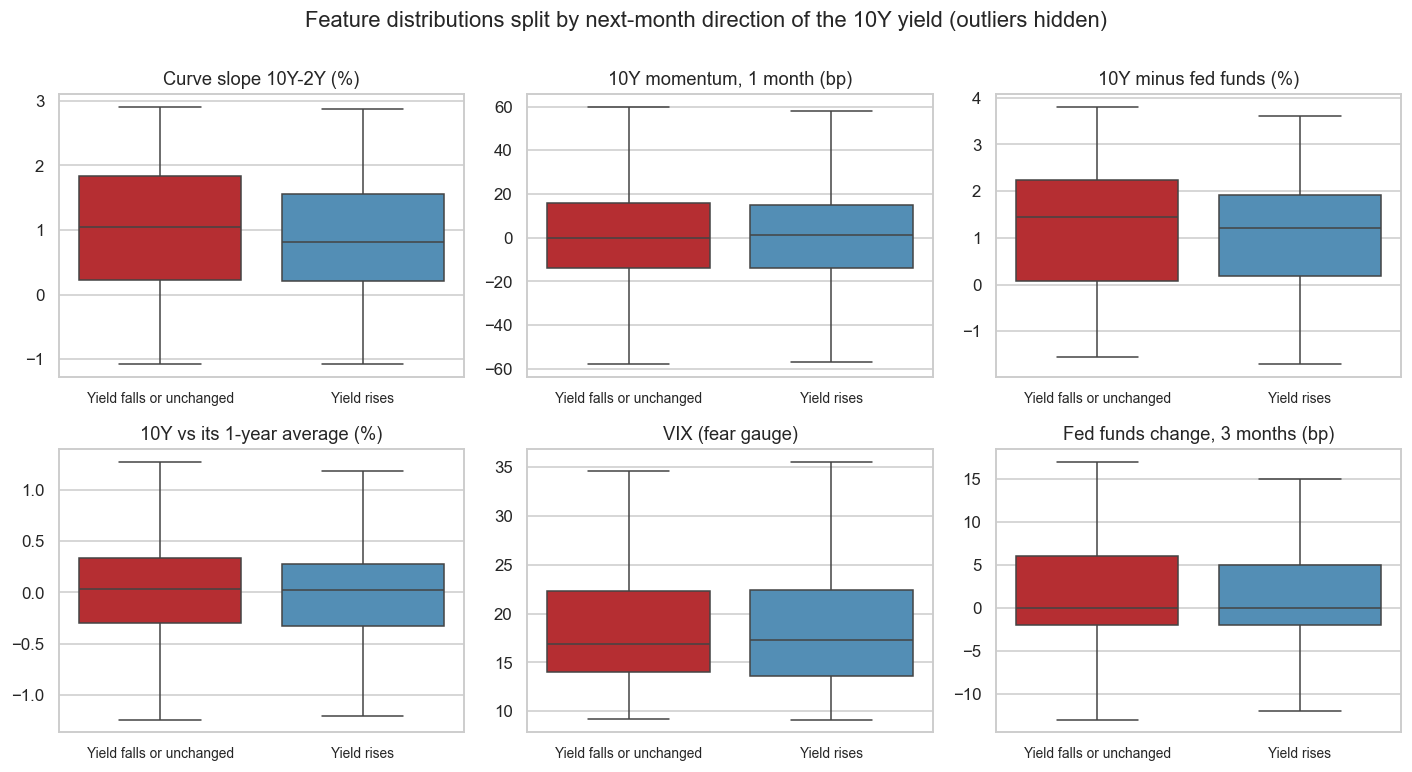

In [15]:
show_features = ["slope_10y_2y", "mom_10y_21d", "spread_10y_fedfunds", "level_10y_vs_1y", "vix", "fedfunds_chg_63d"]
pretty = {"slope_10y_2y": "Curve slope 10Y-2Y (%)", "mom_10y_21d": "10Y momentum, 1 month (bp)",
          "spread_10y_fedfunds": "10Y minus fed funds (%)", "level_10y_vs_1y": "10Y vs its 1-year average (%)",
          "vix": "VIX (fear gauge)", "fedfunds_chg_63d": "Fed funds change, 3 months (bp)"}

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), show_features):
    sns.boxplot(x=target_labels, y=model_df[col], hue=target_labels, palette=["#4292c6", "#cb181d"],
                order=["Yield falls or unchanged", "Yield rises"], legend=False, showfliers=False, ax=ax)
    ax.set_title(pretty[col])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=9)
fig.suptitle("Feature distributions split by next-month direction of the 10Y yield (outliers hidden)", y=1.0)
fig.tight_layout()
plt.show()

The two boxes in each panel overlap heavily. **No single indicator separates rising from falling months on its own** —
a first, honest signal that prediction will be difficult and that any edge must come from combining features.

### 6.8 Descriptive statistics

In [17]:
model_df[FEATURES + ["fwd_chg_10y_bp"]].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

,mean,std,min,25%,50%,75%,max
level_10y_vs_1y,0.00,0.49,-1.65,-0.31,0.03,0.31,1.74
slope_10y_2y,0.99,0.95,-1.08,0.22,0.91,1.72,2.91
slope_10y_3m,1.21,1.31,-1.89,0.20,1.33,2.16,3.83
butterfly_2s5s10s,-0.10,0.26,-0.79,-0.27,-0.11,0.08,0.63
mom_10y_21d,0.14,25.24,-148.00,-14.00,0.00,15.00,93.00
mom_10y_63d,0.19,44.36,-185.00,-27.00,0.00,26.00,150.00
vol_10y_21d,5.31,2.10,1.98,3.79,4.83,6.30,14.47
spread_10y_fedfunds,1.17,1.29,-1.71,0.10,1.30,2.08,3.81
fedfunds_chg_63d,-0.41,46.23,-288.00,-2.00,0.00,6.00,200.00
real_yield_vs_1y,0.01,0.44,-1.20,-0.29,-0.02,0.22,1.87


## 7. Inferential statistics

**(a) Stationarity (Augmented Dickey-Fuller test).** Is the 10-year *level* a random walk? Are its daily *changes*
stable over time? A p-value below 0.05 means "stationary".

**(b) Group differences (Mann-Whitney U test).** For each feature, is its distribution different before rising vs
falling months? We use a non-parametric test because the data are not normal.

In [18]:
adf_results = []
for name, series in [("10Y yield level", clean["10Y"].dropna()), ("10Y daily change", daily_chg_bp)]:
    adf_stat, p_value, *_ = adfuller(series, autolag="AIC")
    adf_results.append({"series": name, "ADF statistic": round(adf_stat, 2), "p-value": round(p_value, 4),
                        "stationary at 5%?": "Yes" if p_value < 0.05 else "No"})
pd.DataFrame(adf_results)

,series,ADF statistic,p-value,stationary at 5%?
0,10Y yield level,-1.84,0.361,No
1,10Y daily change,-59.00,0.000,Yes


In [19]:
up = model_df[model_df["target_up"] == 1]
down = model_df[model_df["target_up"] == 0]

tests = []
for col in FEATURES:
    _, p_value = stats.mannwhitneyu(up[col], down[col])
    tests.append({"feature": col, "median before rise": up[col].median(), "median before fall": down[col].median(),
                  "p-value": p_value})
tests = pd.DataFrame(tests).sort_values("p-value").reset_index(drop=True)
tests.style.format({"median before rise": "{:.2f}", "median before fall": "{:.2f}", "p-value": "{:.1e}"})

,feature,median before rise,median before fall,p-value
0,dollar_ret_21d,-0.23,0.12,1.2e-15
1,oil_ret_21d,2.15,-0.18,1.1e-13
2,butterfly_2s5s10s,-0.14,-0.10,1.7e-10
3,slope_10y_2y,0.81,1.04,3.2e-08
4,cpi_yoy_chg_3m,-0.05,0.13,1.4e-07
5,spread_10y_fedfunds,1.20,1.44,1.5e-07
6,slope_10y_3m,1.24,1.51,1.5e-07
7,real_yield_vs_1y,-0.03,-0.00,1.0e-04
8,level_10y_vs_1y,0.03,0.03,4.3e-03
9,vol_10y_21d,4.83,4.83,9.6e-03


**Interpretation.**

- The yield **level is not stationary** (it behaves like a random walk), while **daily changes are stationary**. This is
  why we predict the *direction of change* rather than the level, and why features are built from spreads and changes.
- Several features show statistically different medians before rises and falls. **Caution:** consecutive days share
  most of their 21-day outcome window, so the observations are not independent and these p-values are too optimistic.
  They show *where to look*, not proof of predictive power — that is what out-of-sample testing in Notebook 3 is for.

## 8. Save the cleaned data for the next notebooks

In [20]:
clean[TENORS + ["fed_funds"]].to_csv(PROCESSED_DIR / "curve_clean.csv")
model_df.to_csv(PROCESSED_DIR / "model_dataset.csv")
pd.Series(MODEL_TENORS, name="tenor").to_csv(PROCESSED_DIR / "model_tenors.csv", index=False)
print(f"Saved: curve_clean.csv {clean.shape}, model_dataset.csv {model_df.shape}, model_tenors.csv")

Saved: curve_clean.csv (6299, 17), model_dataset.csv (5115, 17), model_tenors.csv


## Summary of Notebook 1

- Data from FRED was aligned to the Treasury trading calendar, audited for gaps and stale values, and protected
  against truncated downloads.
- All eleven tenors are complete; CPI is lagged to its publication date to avoid look-ahead bias.
- 15 forward-looking-safe features and a balanced binary target were created.
- EDA shows fat-tailed daily moves, highly correlated maturities, regime-dependent class balance and heavy feature
  overlap between classes — all pointing to a **hard prediction problem where a small edge would be meaningful**.

**Next:** [Notebook 2 — Yield curve PCA and regimes](2_yield_curve_pca_and_regimes.ipynb)